
# Weather Dataset — Exploratory Data Analysis (EDA)

## Objective

Explore temporal and spatial patterns in annual district-level weather data from NASA POWER for 2013–2024.

## Analysis Plan

1. Load and validate the preprocessed weather dataset.
2. Examine annual temperature and precipitation distributions.
3. Analyze year-wise weather trends.
4. Compare weather patterns across states and districts.
5. Investigate precipitation variability and extreme observations.
6. Examine relationships between temperature and precipitation.
7. Evaluate the impact of spatial mapping limitations and quality flags.
8. Document findings, limitations, and potential implications for agricultural analysis.

## Analytical Principles

- Treat correlation as association, not causation.
- Distinguish observed annual patterns from long-term climate trends.
- Do not treat flagged observations as errors without verification.
- Interpret annual precipitation totals and temperature summaries in context.
- Recognize that mapped grid-point estimates may not capture local district-level variation.
- Do not interpret calendar-year summaries as crop-season weather exposure.

## Input

`data/processed/weather_regional/district_weather_annual_preprocessed_2013_2024.csv`

## Expected Output

A documented EDA notebook with reproducible summaries, visualizations, findings, and limitations.


In [2]:

# Cell 2: Load and validate the preprocessed weather dataset

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

project_root = Path.cwd().parent

input_path = (
    project_root
    / "data"
    / "processed"
    / "weather_regional"
    / "district_weather_annual_preprocessed_2013_2024.csv"
)

if not input_path.exists():
    raise FileNotFoundError(f"Dataset not found: {input_path}")

weather_df = pd.read_csv(input_path)

weather_features = [
    "tmin_mean_c",
    "tmin_min_c",
    "tmax_mean_c",
    "tmax_max_c",
    "precipitation_total_mm",
    "precipitation_mean_mm_day",
    "precipitation_max_mm_day"
]

quality_flags = [
    col for col in weather_df.columns
    if col.startswith("QC_")
]

required_columns = [
    "apy_geography_id",
    "calendar_year",
    *weather_features,
    "tmin_valid_days",
    "tmax_valid_days",
    "precipitation_valid_days",
    *quality_flags
]

missing_columns = [
    col for col in required_columns
    if col not in weather_df.columns
]

if missing_columns:
    raise ValueError(f"Missing required columns: {missing_columns}")

print("Dataset shape:", weather_df.shape)
print("Year range:",
      weather_df["calendar_year"].min(),
      "to",
      weather_df["calendar_year"].max())
print("Unique districts:", weather_df["apy_geography_id"].nunique())
print("Missing values:", int(weather_df.isna().sum().sum()))
print("Duplicate district-year keys:",
      int(weather_df.duplicated(
          ["apy_geography_id", "calendar_year"]
      ).sum()))

print("\nWeather features:", weather_features)
print("Quality flags:", quality_flags)

display(weather_df.head())


Dataset shape: (7680, 17)
Year range: 2013 to 2024
Unique districts: 640
Missing values: 0
Duplicate district-year keys: 0

Weather features: ['tmin_mean_c', 'tmin_min_c', 'tmax_mean_c', 'tmax_max_c', 'precipitation_total_mm', 'precipitation_mean_mm_day', 'precipitation_max_mm_day']
Quality flags: ['QC_Extreme_Annual_Min_Temperature', 'QC_Extreme_Annual_Max_Temperature', 'QC_High_Annual_Precipitation', 'QC_Extreme_Daily_Precipitation', 'QC_Long_District_Grid_Distance']


,apy_geography_id,calendar_year,tmin_mean_c,tmin_min_c,tmax_mean_c,tmax_max_c,precipitation_total_mm,precipitation_mean_mm_day,precipitation_max_mm_day,tmin_valid_days,tmax_valid_days,precipitation_valid_days,QC_Extreme_Annual_Min_Temperature,QC_Extreme_Annual_Max_Temperature,QC_High_Annual_Precipitation,QC_Extreme_Daily_Precipitation,QC_Long_District_Grid_Distance
0,APY-GEO-0001,2013,27.472904,25.78,28.279671,30.11,2456.73,6.730767,29.00,365,365,365,False,False,False,False,False
1,APY-GEO-0001,2014,27.517479,25.74,28.430301,30.75,1972.96,5.405370,51.98,365,365,365,False,False,False,False,False
2,APY-GEO-0001,2015,27.664959,26.03,28.533370,30.15,1767.49,4.842438,36.97,365,365,365,False,False,False,False,False
3,APY-GEO-0001,2016,27.918333,25.43,28.810492,31.98,2187.42,5.976557,52.15,366,366,366,False,False,False,False,False
4,APY-GEO-0001,2017,27.570219,25.54,28.360055,29.62,2155.98,5.906795,48.42,365,365,365,False,False,False,False,False


In [3]:

# Cell 3: Aggregate annual weather patterns across districts

annual_weather = (
    weather_df.groupby("calendar_year")
    .agg(
        mean_min_temperature_c=("tmin_mean_c", "mean"),
        mean_max_temperature_c=("tmax_mean_c", "mean"),
        median_min_temperature_c=("tmin_mean_c", "median"),
        median_max_temperature_c=("tmax_mean_c", "median"),
        mean_annual_precipitation_mm=("precipitation_total_mm", "mean"),
        median_annual_precipitation_mm=("precipitation_total_mm", "median"),
        mean_daily_precipitation_mm=("precipitation_mean_mm_day", "mean"),
        mean_max_daily_precipitation_mm=("precipitation_max_mm_day", "mean"),
        districts=("apy_geography_id", "nunique")
    )
    .reset_index()
)

display(annual_weather.round(2))

print("Years analyzed:", len(annual_weather))
print("Minimum districts in a year:", annual_weather["districts"].min())
print("Maximum districts in a year:", annual_weather["districts"].max())


,calendar_year,mean_min_temperature_c,mean_max_temperature_c,median_min_temperature_c,median_max_temperature_c,mean_annual_precipitation_mm,median_annual_precipitation_mm,mean_daily_precipitation_mm,mean_max_daily_precipitation_mm,districts
0,2013,18.60,30.01,19.24,31.42,1333.58,1265.96,3.65,77.45,640
1,2014,18.77,30.61,19.52,32.13,1064.73,968.88,2.92,71.34,640
2,2015,18.93,30.69,19.74,32.31,1193.77,1095.18,3.27,74.35,640
3,2016,19.29,31.09,20.10,32.74,1222.34,1081.99,3.34,63.95,640
4,2017,19.09,30.88,19.98,32.68,1322.01,1037.88,3.62,76.46,640
5,2018,18.85,30.81,19.74,32.54,1138.88,980.32,3.12,61.57,640
6,2019,18.92,30.28,19.77,31.82,1375.51,1186.10,3.77,71.19,640
7,2020,18.55,29.62,19.24,30.87,1484.01,1285.95,4.05,77.82,640
8,2021,18.86,29.99,19.70,31.26,1360.47,1232.88,3.73,70.48,640
9,2022,18.80,30.13,19.61,31.64,1379.84,1217.29,3.78,72.40,640


Years analyzed: 12
Minimum districts in a year: 640
Maximum districts in a year: 640


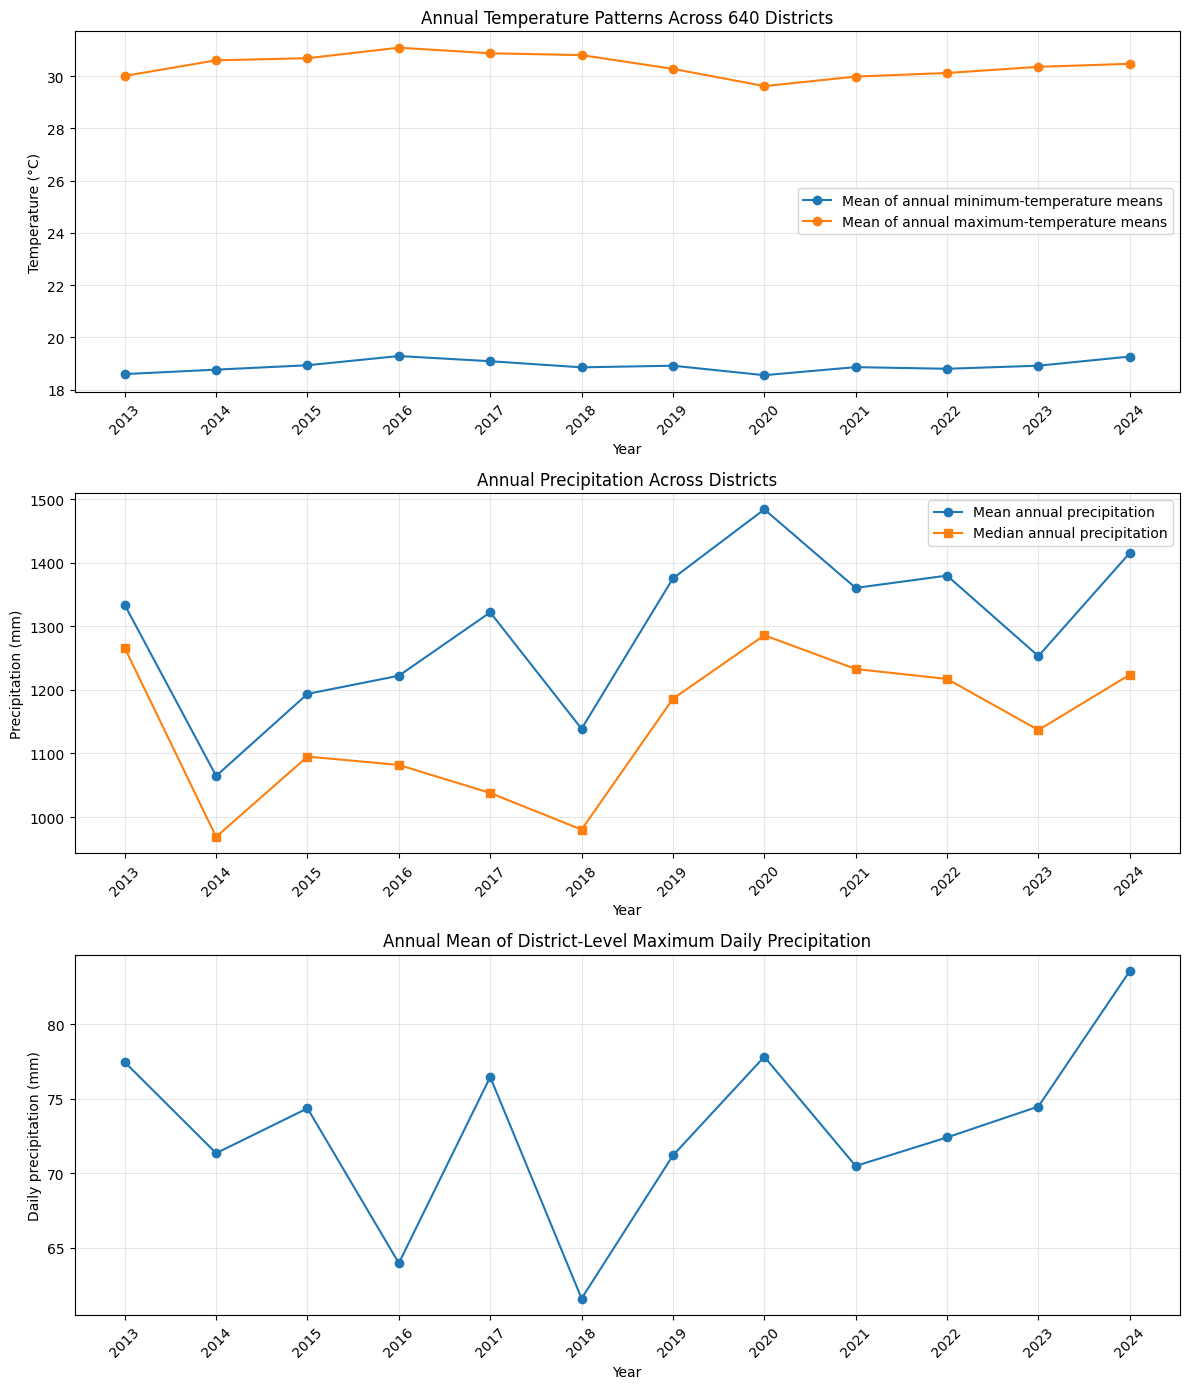

In [4]:

# Cell 4: Visualize annual weather trends

fig, axes = plt.subplots(3, 1, figsize=(12, 14))

# Plot 1: Mean annual temperature summaries
axes[0].plot(
    annual_weather["calendar_year"],
    annual_weather["mean_min_temperature_c"],
    marker="o",
    label="Mean of annual minimum-temperature means"
)
axes[0].plot(
    annual_weather["calendar_year"],
    annual_weather["mean_max_temperature_c"],
    marker="o",
    label="Mean of annual maximum-temperature means"
)
axes[0].set_title("Annual Temperature Patterns Across 640 Districts")
axes[0].set_xlabel("Year")
axes[0].set_ylabel("Temperature (°C)")
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Plot 2: Mean and median annual precipitation
axes[1].plot(
    annual_weather["calendar_year"],
    annual_weather["mean_annual_precipitation_mm"],
    marker="o",
    label="Mean annual precipitation"
)
axes[1].plot(
    annual_weather["calendar_year"],
    annual_weather["median_annual_precipitation_mm"],
    marker="s",
    label="Median annual precipitation"
)
axes[1].set_title("Annual Precipitation Across Districts")
axes[1].set_xlabel("Year")
axes[1].set_ylabel("Precipitation (mm)")
axes[1].legend()
axes[1].grid(True, alpha=0.3)

# Plot 3: Mean of district-level maximum daily precipitation
axes[2].plot(
    annual_weather["calendar_year"],
    annual_weather["mean_max_daily_precipitation_mm"],
    marker="o"
)
axes[2].set_title("Annual Mean of District-Level Maximum Daily Precipitation")
axes[2].set_xlabel("Year")
axes[2].set_ylabel("Daily precipitation (mm)")
axes[2].grid(True, alpha=0.3)

for ax in axes:
    ax.set_xticks(annual_weather["calendar_year"])
    ax.tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


In [5]:

# Cell 5: Examine the distribution of annual precipitation

precipitation_summary = weather_df[
    "precipitation_total_mm"
].describe(
    percentiles=[0.01, 0.05, 0.25, 0.50, 0.75, 0.95, 0.99]
).to_frame("Annual precipitation (mm)")

display(precipitation_summary.round(2))

print(
    "Skewness:",
    round(weather_df["precipitation_total_mm"].skew(), 3)
)

print(
    "District-year records above 3000 mm:",
    int((weather_df["precipitation_total_mm"] > 3000).sum())
)

print(
    "District-year records above 5000 mm:",
    int((weather_df["precipitation_total_mm"] > 5000).sum())
)


,Annual precipitation (mm)
count,7680.00
mean,1295.31
std,681.74
min,136.26
1%,381.52
5%,539.08
25%,857.77
50%,1141.54
75%,1522.84
95%,2638.77


Skewness: 1.951
District-year records above 3000 mm: 230
District-year records above 5000 mm: 13


In [7]:

# Cell 6: Inspect the wettest district-year records

metadata_path = (
    project_root
    / "data"
    / "processed"
    / "weather_regional"
    / "district_weather_annual_cleaned_flagged_2013_2024.csv"
)

metadata_columns = [
    "apy_geography_id",
    "State",
    "District",
    "nearest_grid_distance_km"
]

metadata_df = pd.read_csv(
    metadata_path,
    usecols=metadata_columns
).drop_duplicates(subset=["apy_geography_id"])

wettest_records = (
    weather_df.merge(
        metadata_df,
        on="apy_geography_id",
        how="left",
        validate="many_to_one"
    )
    .nlargest(15, "precipitation_total_mm")
    [[
        "State",
        "District",
        "calendar_year",
        "precipitation_total_mm",
        "precipitation_max_mm_day",
        "nearest_grid_distance_km",
        "QC_High_Annual_Precipitation",
        "QC_Extreme_Daily_Precipitation",
        "QC_Long_District_Grid_Distance"
    ]]
)

display(wettest_records.round(2))

print(
    "Records without matched geography:",
    int(wettest_records["State"].isna().sum())
)


,State,District,calendar_year,precipitation_total_mm,precipitation_max_mm_day,nearest_grid_distance_km,QC_High_Annual_Precipitation,QC_Extreme_Daily_Precipitation,QC_Long_District_Grid_Distance
6508,Tripura,South Tripura,2017,6693.07,271.00,33.32,True,False,True
4408,Mizoram,Lawngtlai,2017,5994.72,307.60,27.88,True,True,True
4420,Mizoram,Lunglei,2017,5523.71,291.33,14.72,True,False,False
4243,Meghalaya,East Khasi Hills,2020,5363.19,168.46,12.25,True,False,False
4327,Meghalaya,West Jaintia Hills,2020,5363.19,168.46,31.67,True,False,True
4303,Meghalaya,South West Khasi Hills,2020,5317.55,164.57,22.44,True,False,False
4339,Meghalaya,West Khasi Hills,2020,5317.55,164.57,15.78,True,False,False
6496,Tripura,Sepahijala,2017,5294.51,210.39,6.04,True,False,False
4300,Meghalaya,South West Khasi Hills,2017,5267.42,258.99,22.44,True,False,False
4336,Meghalaya,West Khasi Hills,2017,5267.42,258.99,15.78,True,False,False


Records without matched geography: 0


In [8]:

# Cell 7: Identify repeated precipitation profiles across districts

precipitation_profiles = (
    weather_df.groupby(
        [
            "calendar_year",
            "precipitation_total_mm",
            "precipitation_max_mm_day"
        ]
    )
    .agg(
        district_count=("apy_geography_id", "nunique"),
        districts=("apy_geography_id", lambda x: ", ".join(sorted(x.unique())))
    )
    .reset_index()
)

repeated_profiles = (
    precipitation_profiles[
        precipitation_profiles["district_count"] > 1
    ]
    .sort_values(
        ["district_count", "calendar_year"],
        ascending=[False, True]
    )
)

print("Repeated annual precipitation profiles:",
      len(repeated_profiles))
print("Profiles shared by 3 or more districts:",
      int((repeated_profiles["district_count"] >= 3).sum()))

display(repeated_profiles.head(15))


Repeated annual precipitation profiles: 1224
Profiles shared by 3 or more districts: 216


,calendar_year,precipitation_total_mm,precipitation_max_mm_day,district_count,districts
325,2013,1473.48,37.96,4,"APY-GEO-0074, APY-GEO-0441, APY-GEO-0442, APY-..."
336,2013,1494.13,70.56,4,"APY-GEO-0415, APY-GEO-0418, APY-GEO-0444, APY-..."
880,2014,1170.83,47.30,4,"APY-GEO-0415, APY-GEO-0418, APY-GEO-0444, APY-..."
922,2014,1294.07,32.06,4,"APY-GEO-0074, APY-GEO-0441, APY-GEO-0442, APY-..."
1478,2015,1618.03,57.80,4,"APY-GEO-0415, APY-GEO-0418, APY-GEO-0444, APY-..."
1485,2015,1691.95,55.08,4,"APY-GEO-0074, APY-GEO-0441, APY-GEO-0442, APY-..."
1976,2016,1528.37,69.60,4,"APY-GEO-0415, APY-GEO-0418, APY-GEO-0444, APY-..."
1984,2016,1577.01,56.65,4,"APY-GEO-0074, APY-GEO-0441, APY-GEO-0442, APY-..."
2518,2017,1947.09,65.23,4,"APY-GEO-0074, APY-GEO-0441, APY-GEO-0442, APY-..."
2519,2017,1957.85,55.99,4,"APY-GEO-0415, APY-GEO-0418, APY-GEO-0444, APY-..."


In [9]:

# Cell 8: Verify repeated precipitation profiles against grid coordinates

grid_metadata = (
    pd.read_csv(
        metadata_path,
        usecols=[
            "apy_geography_id",
            "nearest_grid_latitude",
            "nearest_grid_longitude",
            "nearest_grid_distance_km"
        ]
    )
    .drop_duplicates(subset=["apy_geography_id"])
)

grid_weather_df = weather_df.merge(
    grid_metadata,
    on="apy_geography_id",
    how="left",
    validate="many_to_one"
)

# Count unique grid points represented by each repeated profile
profile_grid_check = (
    grid_weather_df.groupby(
        [
            "calendar_year",
            "precipitation_total_mm",
            "precipitation_max_mm_day"
        ]
    )
    .agg(
        district_count=("apy_geography_id", "nunique"),
        unique_grid_points=(
            ["nearest_grid_latitude", "nearest_grid_longitude"],
            "nunique"
        ) if False else (
            "apy_geography_id", "nunique"
        )
    )
    .reset_index()
)

# Calculate unique coordinate pairs explicitly
profile_grid_check["unique_grid_points"] = (
    grid_weather_df.groupby(
        [
            "calendar_year",
            "precipitation_total_mm",
            "precipitation_max_mm_day"
        ]
    )
    .apply(
        lambda group: group[
            ["nearest_grid_latitude", "nearest_grid_longitude"]
        ].drop_duplicates().shape[0],
        include_groups=False
    )
    .to_numpy()
)

profile_grid_check["districts_per_grid_point"] = (
    profile_grid_check["district_count"]
    / profile_grid_check["unique_grid_points"]
)

repeated_grid_profiles = profile_grid_check[
    profile_grid_check["district_count"] > 1
].sort_values(
    ["unique_grid_points", "district_count"],
    ascending=[True, False]
)

print("Repeated precipitation profiles:",
      len(repeated_grid_profiles))
print(
    "Repeated profiles where all districts map to one grid point:",
    int((repeated_grid_profiles["unique_grid_points"] == 1).sum())
)
print(
    "Repeated profiles spanning multiple grid points:",
    int((repeated_grid_profiles["unique_grid_points"] > 1).sum())
)

display(repeated_grid_profiles.head(15))


Repeated precipitation profiles: 1224
Repeated profiles where all districts map to one grid point: 1224
Repeated profiles spanning multiple grid points: 0


,calendar_year,precipitation_total_mm,precipitation_max_mm_day,district_count,unique_grid_points,districts_per_grid_point
325,2013,1473.48,37.96,4,1,4.0
336,2013,1494.13,70.56,4,1,4.0
880,2014,1170.83,47.30,4,1,4.0
922,2014,1294.07,32.06,4,1,4.0
1478,2015,1618.03,57.80,4,1,4.0
1485,2015,1691.95,55.08,4,1,4.0
1976,2016,1528.37,69.60,4,1,4.0
1984,2016,1577.01,56.65,4,1,4.0
2518,2017,1947.09,65.23,4,1,4.0
2519,2017,1957.85,55.99,4,1,4.0


In [10]:

# Cell 9: Quantify district-to-grid mapping coverage

grid_mapping_summary = (
    grid_metadata.groupby(
        ["nearest_grid_latitude", "nearest_grid_longitude"]
    )
    .agg(
        district_count=("apy_geography_id", "nunique"),
        mean_mapping_distance_km=("nearest_grid_distance_km", "mean"),
        max_mapping_distance_km=("nearest_grid_distance_km", "max")
    )
    .reset_index()
    .sort_values("district_count", ascending=False)
)

print("Total districts:", grid_metadata["apy_geography_id"].nunique())
print(
    "Unique mapped grid points:",
    grid_mapping_summary.shape[0]
)
print(
    "Grid points mapped to multiple districts:",
    int((grid_mapping_summary["district_count"] > 1).sum())
)
print(
    "Maximum districts mapped to one grid point:",
    int(grid_mapping_summary["district_count"].max())
)

print("\nDistribution of districts per grid point:")
display(
    grid_mapping_summary["district_count"]
    .value_counts()
    .sort_index()
    .rename_axis("Districts per grid point")
    .to_frame("Number of grid points")
)

print("\nTop 10 most-shared grid points:")
display(grid_mapping_summary.head(10).round(2))


Total districts: 640
Unique mapped grid points: 518
Grid points mapped to multiple districts: 102
Maximum districts mapped to one grid point: 4

Distribution of districts per grid point:


,Number of grid points
Districts per grid point,
1,416
2,84
3,16
4,2



Top 10 most-shared grid points:


,nearest_grid_latitude,nearest_grid_longitude,district_count,mean_mapping_distance_km,max_mapping_distance_km
327,25.5,94.38,4,25.57,36.88
354,26.0,93.75,4,23.44,30.87
445,28.0,94.38,3,29.98,37.10
436,28.0,76.88,3,25.10,37.65
514,34.0,75.00,3,20.58,31.62
489,30.5,76.88,3,23.54,27.09
379,26.5,91.25,3,21.24,24.75
293,25.0,85.62,3,25.39,29.49
299,25.0,93.75,3,26.73,30.87
294,25.0,86.25,3,27.62,36.31


In [11]:

# Cell 10: Summarize temperature variability across districts

temperature_columns = [
    "tmin_mean_c",
    "tmin_min_c",
    "tmax_mean_c",
    "tmax_max_c"
]

temperature_summary = weather_df[
    temperature_columns
].agg(["mean", "std", "min", "median", "max"]).T

temperature_summary["range_c"] = (
    temperature_summary["max"] - temperature_summary["min"]
)

temperature_summary["coefficient_of_variation_pct"] = (
    weather_df[temperature_columns].std()
    / weather_df[temperature_columns].mean().abs()
    * 100
)

display(temperature_summary.round(2))

print("\nTemperature quality-flag counts:")
display(
    weather_df[
        [
            "QC_Extreme_Annual_Min_Temperature",
            "QC_Extreme_Annual_Max_Temperature"
        ]
    ].sum().astype(int).to_frame("Flagged district-year records")
)


,mean,std,min,median,max,range_c,coefficient_of_variation_pct
tmin_mean_c,18.90,4.34,-11.80,19.66,28.33,40.13,22.97
tmin_min_c,5.68,6.49,-35.46,5.19,26.44,61.90,114.32
tmax_mean_c,30.41,4.81,-0.89,31.85,36.64,37.53,15.82
tmax_max_c,42.02,6.19,14.19,44.10,49.84,35.65,14.73



Temperature quality-flag counts:


,Flagged district-year records
QC_Extreme_Annual_Min_Temperature,11
QC_Extreme_Annual_Max_Temperature,498


In [12]:

# Cell 11: Inspect temperature extremes

temperature_metadata = pd.read_csv(
    metadata_path,
    usecols=[
        "apy_geography_id",
        "State",
        "District",
        "nearest_grid_distance_km"
    ]
).drop_duplicates(subset=["apy_geography_id"])

temperature_extremes = weather_df.merge(
    temperature_metadata,
    on="apy_geography_id",
    how="left",
    validate="many_to_one"
)

inspect_columns = [
    "State",
    "District",
    "calendar_year",
    "tmin_mean_c",
    "tmin_min_c",
    "tmax_mean_c",
    "tmax_max_c",
    "QC_Extreme_Annual_Min_Temperature",
    "QC_Extreme_Annual_Max_Temperature",
    "nearest_grid_distance_km"
]

print("10 coldest annual minimum temperatures:")
display(
    temperature_extremes.nsmallest(10, "tmin_min_c")[inspect_columns]
    .round(2)
)

print("10 hottest annual maximum temperatures:")
display(
    temperature_extremes.nlargest(10, "tmax_max_c")[inspect_columns]
    .round(2)
)


10 coldest annual minimum temperatures:


,State,District,calendar_year,tmin_mean_c,tmin_min_c,tmax_mean_c,tmax_max_c,QC_Extreme_Annual_Min_Temperature,QC_Extreme_Annual_Max_Temperature,nearest_grid_distance_km
3054,Ladakh,Kargil,2019,-11.57,-35.46,-0.78,15.35,True,False,27.54
3055,Ladakh,Kargil,2020,-11.80,-33.16,-0.89,15.58,True,False,27.54
3057,Ladakh,Kargil,2022,-10.31,-32.09,0.41,16.42,True,False,27.54
3053,Ladakh,Kargil,2018,-10.80,-31.36,0.20,16.99,True,False,27.54
3059,Ladakh,Kargil,2024,-9.83,-31.33,0.75,17.21,True,False,27.54
3052,Ladakh,Kargil,2017,-9.77,-31.21,0.29,15.20,True,False,27.54
2419,Himachal Pradesh,Kullu,2020,-7.00,-30.98,3.62,14.62,True,False,14.37
2418,Himachal Pradesh,Kullu,2019,-7.18,-30.48,3.37,15.77,True,False,14.37
3058,Ladakh,Kargil,2023,-10.42,-30.37,0.02,15.76,True,False,27.54
2406,Himachal Pradesh,Kinnaur,2019,-5.50,-30.25,6.08,19.22,True,False,22.19


10 hottest annual maximum temperatures:


,State,District,calendar_year,tmin_mean_c,tmin_min_c,tmax_mean_c,tmax_max_c,QC_Extreme_Annual_Min_Temperature,QC_Extreme_Annual_Max_Temperature,nearest_grid_distance_km
6937,Uttar Pradesh,Hamirpur,2014,20.16,4.45,34.14,49.84,False,True,24.08
6685,Uttar Pradesh,Banda,2014,20.22,5.47,33.81,49.69,False,True,9.07
7129,Uttar Pradesh,Mahoba,2014,20.11,5.31,33.77,49.69,False,True,33.29
3407,Madhya Pradesh,Morena,2024,19.80,3.65,32.40,49.62,False,True,29.33
6853,Uttar Pradesh,Fatehpur,2014,20.06,4.18,33.94,49.62,False,True,34.37
6985,Uttar Pradesh,Jalaun,2014,19.91,4.82,33.67,49.62,False,True,11.76
6551,Uttar Pradesh,Agra,2024,19.61,3.47,32.46,49.56,False,True,24.64
3155,Madhya Pradesh,Bhind,2024,19.84,3.85,32.34,49.54,False,True,17.77
5279,Rajasthan,Bharatpur,2024,19.47,3.31,32.47,49.54,False,True,20.75
5387,Rajasthan,Ganganagar,2024,20.57,4.76,34.35,49.53,False,True,16.59


In [13]:

# Cell 12: Summarize flagged versus unflagged temperature records

max_temp_flag_summary = (
    weather_df.groupby("QC_Extreme_Annual_Max_Temperature")
    .agg(
        records=("apy_geography_id", "size"),
        districts=("apy_geography_id", "nunique"),
        mean_annual_max_c=("tmax_max_c", "mean"),
        median_annual_max_c=("tmax_max_c", "median"),
        minimum_annual_max_c=("tmax_max_c", "min"),
        maximum_annual_max_c=("tmax_max_c", "max")
    )
)

print("Flagged vs unflagged annual maximum temperatures:")
display(max_temp_flag_summary.round(2))

print("\nFlagged records by year:")
display(
    weather_df.groupby("calendar_year")[
        "QC_Extreme_Annual_Max_Temperature"
    ].agg(["sum", "count"]).rename(
        columns={"sum": "flagged_records", "count": "total_records"}
    ).assign(
        flagged_pct=lambda x: (
            x["flagged_records"] / x["total_records"] * 100
        )
    ).round(2)
)


Flagged vs unflagged annual maximum temperatures:


,records,districts,mean_annual_max_c,median_annual_max_c,minimum_annual_max_c,maximum_annual_max_c
QC_Extreme_Annual_Max_Temperature,,,,,,
False,7182,640,41.57,43.76,14.19,48.00
True,498,184,48.49,48.40,48.01,49.84



Flagged records by year:


,flagged_records,total_records,flagged_pct
calendar_year,,,
2013,51,640,7.97
2014,89,640,13.91
2015,31,640,4.84
2016,30,640,4.69
2017,40,640,6.25
2018,0,640,0.00
2019,68,640,10.62
2020,18,640,2.81
2021,0,640,0.00


In [14]:

# Cell 13: Compare annual mean and extreme maximum temperatures

annual_temperature_check = (
    weather_df.groupby("calendar_year")
    .agg(
        mean_tmax_mean_c=("tmax_mean_c", "mean"),
        median_tmax_mean_c=("tmax_mean_c", "median"),
        mean_tmax_max_c=("tmax_max_c", "mean"),
        median_tmax_max_c=("tmax_max_c", "median"),
        max_tmax_max_c=("tmax_max_c", "max"),
        flagged_records=("QC_Extreme_Annual_Max_Temperature", "sum")
    )
    .reset_index()
)

display(annual_temperature_check.round(2))


,calendar_year,mean_tmax_mean_c,median_tmax_mean_c,mean_tmax_max_c,median_tmax_max_c,max_tmax_max_c,flagged_records
0,2013,30.01,31.42,42.40,44.33,48.69,51
1,2014,30.61,32.13,42.56,44.66,49.84,89
2,2015,30.69,32.31,41.85,44.62,48.72,31
3,2016,31.09,32.74,42.36,44.99,48.87,30
4,2017,30.88,32.68,42.02,44.42,48.87,40
5,2018,30.81,32.54,41.48,43.93,47.81,0
6,2019,30.28,31.82,42.56,45.08,48.91,68
7,2020,29.62,30.87,41.64,43.87,48.39,18
8,2021,29.99,31.26,40.44,42.28,47.47,0
9,2022,30.13,31.64,41.99,44.19,48.90,26


,tmin_mean_c,tmin_min_c,tmax_mean_c,tmax_max_c,precipitation_total_mm,precipitation_mean_mm_day,precipitation_max_mm_day
tmin_mean_c,1.00,0.87,0.90,0.66,-0.02,-0.02,0.07
tmin_min_c,0.87,1.00,0.65,0.29,0.14,0.14,0.09
tmax_mean_c,0.90,0.65,1.00,0.88,-0.30,-0.30,-0.03
tmax_max_c,0.66,0.29,0.88,1.00,-0.42,-0.43,-0.04
precipitation_total_mm,-0.02,0.14,-0.30,-0.42,1.00,1.00,0.52
precipitation_mean_mm_day,-0.02,0.14,-0.30,-0.43,1.00,1.00,0.52
precipitation_max_mm_day,0.07,0.09,-0.03,-0.04,0.52,0.52,1.00


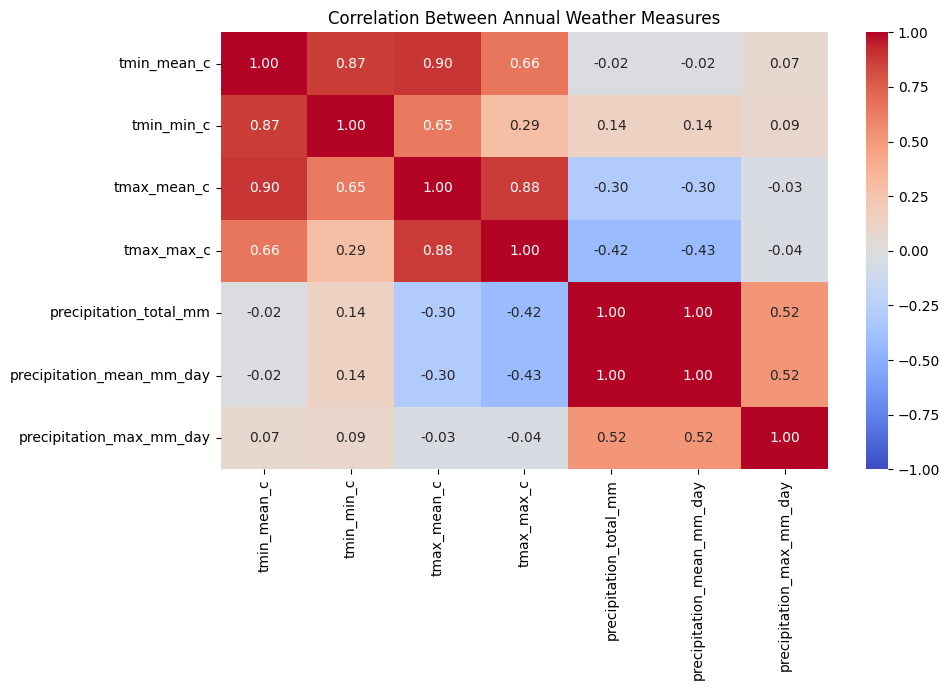

In [15]:

# Cell 14: Correlation analysis of weather measures

correlation_columns = [
    "tmin_mean_c",
    "tmin_min_c",
    "tmax_mean_c",
    "tmax_max_c",
    "precipitation_total_mm",
    "precipitation_mean_mm_day",
    "precipitation_max_mm_day"
]

weather_correlation = weather_df[correlation_columns].corr()

display(weather_correlation.round(2))

plt.figure(figsize=(10, 7))
sns.heatmap(
    weather_correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1
)
plt.title("Correlation Between Annual Weather Measures")
plt.tight_layout()
plt.show()


In [16]:

# Cell 15: Year-wise temperature–precipitation correlations

yearly_correlations = []

for year, group in weather_df.groupby("calendar_year"):
    yearly_correlations.append({
        "calendar_year": year,
        "corr_tmax_mean_vs_precip": group[
            "tmax_mean_c"
        ].corr(group["precipitation_total_mm"]),
        "corr_tmax_max_vs_precip": group[
            "tmax_max_c"
        ].corr(group["precipitation_total_mm"]),
        "corr_tmin_mean_vs_precip": group[
            "tmin_mean_c"
        ].corr(group["precipitation_total_mm"]),
        "districts": group["apy_geography_id"].nunique()
    })

yearly_correlations_df = pd.DataFrame(yearly_correlations)

display(yearly_correlations_df.round(3))


,calendar_year,corr_tmax_mean_vs_precip,corr_tmax_max_vs_precip,corr_tmin_mean_vs_precip,districts
0,2013,-0.186,-0.257,0.051,640
1,2014,-0.250,-0.380,0.049,640
2,2015,-0.365,-0.530,-0.029,640
3,2016,-0.311,-0.422,-0.020,640
4,2017,-0.342,-0.530,-0.037,640
5,2018,-0.393,-0.485,-0.097,640
6,2019,-0.227,-0.417,-0.012,640
7,2020,-0.296,-0.472,-0.011,640
8,2021,-0.219,-0.331,0.087,640
9,2022,-0.338,-0.483,-0.077,640


In [17]:

# Cell 16: Consolidate key weather EDA findings

weather_eda_summary = pd.DataFrame([
    {
        "Area": "Coverage",
        "Finding": "7,680 district-year records across 640 districts from 2013–2024."
    },
    {
        "Area": "Completeness",
        "Finding": "No missing values or duplicate district-year keys in the preprocessed dataset."
    },
    {
        "Area": "Temperature",
        "Finding": "Mean district-level tmin_mean_c is 18.90°C and tmax_mean_c is 30.41°C."
    },
    {
        "Area": "Temperature QC",
        "Finding": "11 annual minimum-temperature records and 498 annual maximum-temperature records are flagged."
    },
    {
        "Area": "Precipitation",
        "Finding": "Annual precipitation is right-skewed; mean is about 1,295 mm and median about 1,142 mm."
    },
    {
        "Area": "Spatial mapping",
        "Finding": "640 districts map to 518 grid points; 102 grid points are shared by multiple districts."
    },
    {
        "Area": "Correlations",
        "Finding": "Maximum-temperature measures are negatively correlated with annual precipitation across every year."
    },
    {
        "Area": "Interpretation limits",
        "Finding": "Annual calendar-year summaries are not crop-season weather; correlations are descriptive, and shared grid points reduce spatial independence."
    }
])

display(weather_eda_summary)


,Area,Finding
0,Coverage,"7,680 district-year records across 640 distric..."
1,Completeness,No missing values or duplicate district-year k...
2,Temperature,Mean district-level tmin_mean_c is 18.90°C and...
3,Temperature QC,11 annual minimum-temperature records and 498 ...
4,Precipitation,Annual precipitation is right-skewed; mean is ...
5,Spatial mapping,640 districts map to 518 grid points; 102 grid...
6,Correlations,Maximum-temperature measures are negatively co...
7,Interpretation limits,Annual calendar-year summaries are not crop-se...


## Conclusion

The weather EDA examined 7,680 annual district-level records covering 640 districts across 2013–2024. The preprocessed dataset contains no missing values or duplicate district-year keys, providing a consistent basis for descriptive analysis.

Annual precipitation is right-skewed, with a mean of approximately 1,295 mm and a median of approximately 1,142 mm. Temperature measures show strong positive relationships with one another, while annual precipitation has a negative correlation with maximum-temperature measures across all 12 years. These correlations describe associations and do not establish causation.

Quality-control flags identify extreme temperature and precipitation observations for review; flagged values were retained rather than automatically removed. Spatial mapping also requires caution: 640 districts map to 518 unique weather grid points, and some grid points serve multiple districts.

These data represent calendar-year summaries derived from gridded weather estimates. They should not be interpreted as crop-season weather or precise measurements at every district location. Further crop-specific analysis should account for these limitations and validate the suitability of the weather variables for the intended task.